# BSP project

*Giacomo Sacco 82389A*

Algorithm implemetation of the paper:

"A wavelet-based ECG delineation algorithm for 32-bit integer online processing" (2011) by Luigi Di Marco and Lorenzo Chiari

In [1]:
import numpy as np
import pywt
from scipy.signal import find_peaks, resample
import wfdb
import matplotlib.pyplot as plt
# Import custom modules
from ecg_utils import load_ecg, load_annotations, plot_ecg, plot_ecg_interactive, load_ecg_int, plot_wavelet_details
from preprocessing import preprocessing
from integer_wavelet_transform import integer_wavelet_transform
from qrs_detection import qrs_detection
from qrs_delineation import qrs_delineation
from p_delineation import p_delineation
from t_delineation import t_delineation

In [2]:
# MIT-BIH Arrhythmia Database record names
# mit_bih_records = [
#     '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
#     '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
#     '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
#     '209', '210', '212', '213', '214', '215', '217', '219', '220', '221',
#     '222', '223', '228', '230', '231', '232', '233', '234'
# ]
# current = 29
# path = "../data/mit-bih-arrhythmia-database-1.0.0"
# len(mit_bih_records)

In [3]:
#ecg, fs, record = load_ecg_int(mit_bih_records[current], path)
#annotations = load_annotations(mit_bih_records[current], path)

In [4]:
# Load QT Database records
edb_path = "../data/european-st-t-database-1.0.0"
qtdb_path = "../data/qt-database-1.0.0"
ecg, fs, record = load_ecg_int("sel100", qtdb_path)
ecg_p, _, _ = load_ecg("sel100", qtdb_path)         # signal with physical values (mV)
annotations = load_annotations("sel100", qtdb_path, extension='q1c')

## Preprocessing
downsample to 250 sample/s

In [5]:
if fs != 250:
    ecg, fs = preprocessing(ecg, fs, 250)

## Online QRS detection and P-QRS-T delineation

### DWT decomposition

In [6]:
details = integer_wavelet_transform(ecg, 3)

###  QRS-complex detection (r peak)


In [7]:
r_peaks, qrs_d2_peaks_pos = qrs_detection(details, fs)
len(r_peaks), len(qrs_d2_peaks_pos)

(1135, 1135)

###  QRS-complex delineation (onset/offset)

In [8]:
QRS_onsets, QRS_offsets = qrs_delineation(details, fs, r_peaks, qrs_d2_peaks_pos)


### P wave delineation (mono & biphasic)

In [9]:
p_peaks, p_onsets, p_offsets = p_delineation(details, fs, QRS_onsets, r_peaks)

### T wave delineation (mono & biphasic)

In [10]:
t_peaks, t_offsets, t_ends = t_delineation(details, fs, QRS_offsets, r_peaks)

## Results

In [11]:
# Analyze the detection results
total_qrs = len(r_peaks)
total_p = sum(1 for p in p_peaks if p is not None)
total_t = sum(1 for t in t_peaks if t is not None)

print("=" * 60)
print("ECG DELINEATION RESULTS")
print("=" * 60)
print(f"Sampling frequency: {fs} Hz")
print(f"Signal duration: {len(ecg)/fs:.2f} seconds")
print("-" * 60)
print(f"QRS complexes detected: {total_qrs}")
print(f"P waves detected: {total_p} ({total_p/total_qrs*100:.1f}%)")
print(f"T waves detected: {total_t} ({total_t/total_qrs*100:.1f}%)")
print("-" * 60)

# Calculate average durations
qrs_durations = [(QRS_offsets[i] - QRS_onsets[i]) / fs * 1000 for i in range(len(QRS_onsets))]
p_durations = [(p_offsets[i] - p_onsets[i]) / fs * 1000 for i, p in enumerate(p_offsets) if p is not None and p_onsets[i] is not None]

print(f"Average QRS duration: {np.mean(qrs_durations):.1f} ± {np.std(qrs_durations):.1f} ms")
if len(p_durations) > 0:
    print(f"Average P wave duration: {np.mean(p_durations):.1f} ± {np.std(p_durations):.1f} ms")

# Calculate heart rate
if len(r_peaks) > 1:
    rr_intervals = np.diff(r_peaks) / fs
    heart_rate = 60 / np.mean(rr_intervals)
    print(f"Average heart rate: {heart_rate:.1f} bpm")
print("=" * 60)

ECG DELINEATION RESULTS
Sampling frequency: 250 Hz
Signal duration: 900.00 seconds
------------------------------------------------------------
QRS complexes detected: 1135
P waves detected: 746 (65.7%)
T waves detected: 1134 (99.9%)
------------------------------------------------------------
Average QRS duration: 119.6 ± 21.9 ms
Average P wave duration: 121.3 ± 19.8 ms
Average heart rate: 75.7 bpm


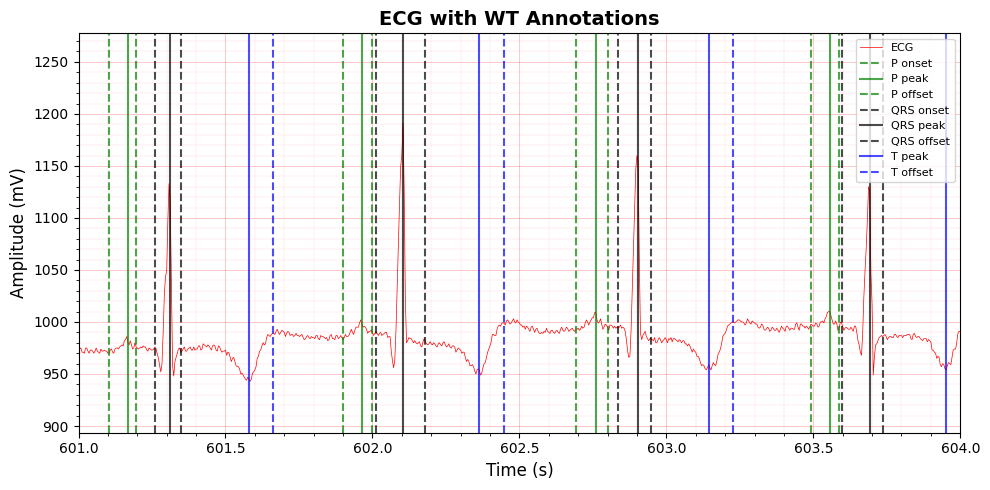

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


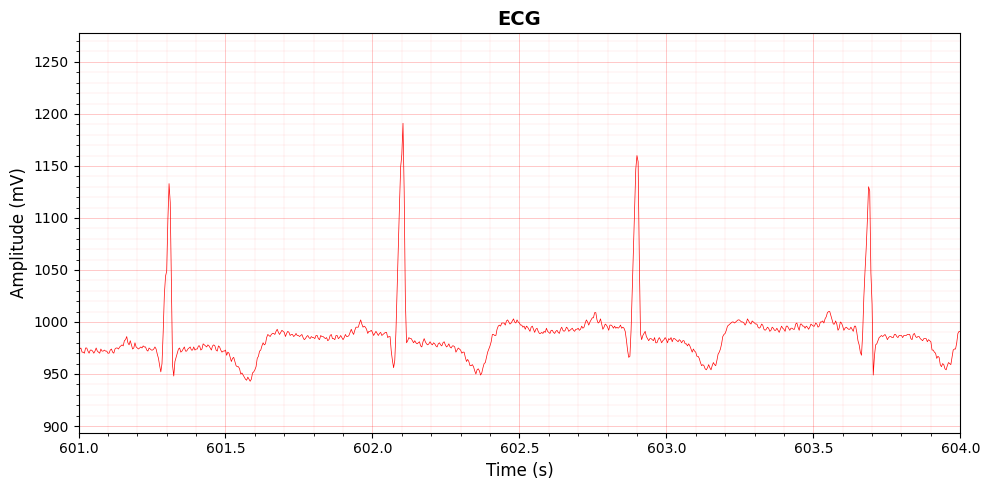

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


In [12]:
qrs_events={'onset': QRS_onsets, 'offset': QRS_offsets, 'peak': r_peaks}
p_events={'onset': p_onsets, 'offset': p_offsets, 'peak': p_peaks}
t_events={'peak': t_peaks, 'offset': t_offsets, 'end': t_ends}
start = 601
plot_ecg(ecg, fs, time_range=(start, start+3), qrs_events=qrs_events, p_events=p_events, t_events=t_events, title="ECG with WT Annotations")
plot_ecg(ecg, fs, time_range=(start, start+3), title="ECG")
#plot_ecg_interactive(ecg, fs, time_range=(start, start+3), qrs_events=qrs_events, p_events=p_events, t_events=t_events)

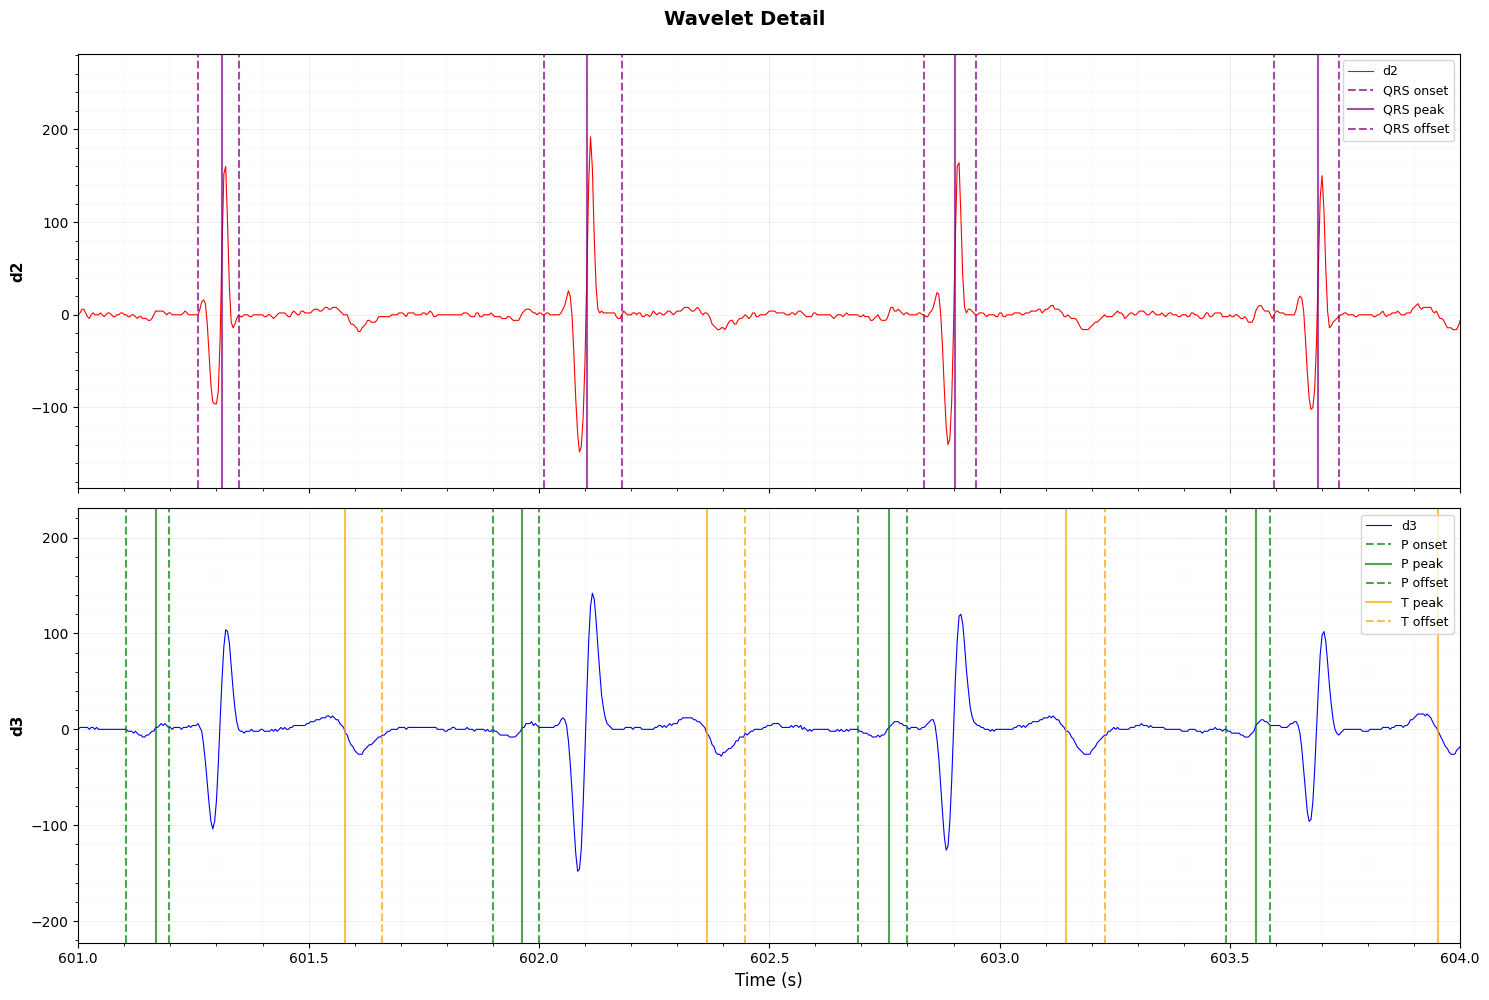

Number of detail levels: 2
Sampling frequency: 250 Hz
Time range: 601.00s - 604.00s


In [13]:
plot_wavelet_details(details, fs, time_range=(start, start+3), 
                     p_events=p_events, qrs_events=qrs_events, t_events=t_events, levels=[2,3])

Ground truth annotations extracted:
  R-peaks: 30
  QRS onsets: 30
  QRS offsets: 30
  P-peaks: 30
  P-onsets: 30
  P-offsets: 30
  T-peaks: 30
  T-offsets: 30


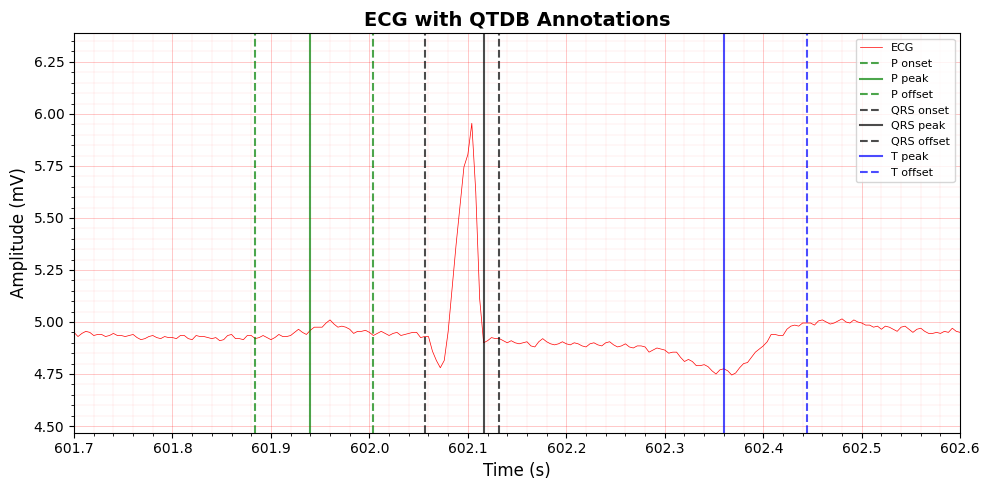

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


In [14]:
qtdb_path = "../data/qt-database-1.0.0"
ecg, fs, record = load_ecg_int("sel100", qtdb_path)
annotations = load_annotations("sel100", qtdb_path, extension='q1c')

# Extract fiducial points from QT Database annotations
ann_samples = annotations.sample
ann_symbols = annotations.symbol

# Initialize ground truth event lists
gt_r_peaks = []
gt_QRS_onsets = []
gt_QRS_offsets = []
gt_p_peaks = []
gt_p_onsets = []
gt_p_offsets = []
gt_t_peaks = []
gt_t_offsets = []

# Map annotation symbols to events
# QT Database annotation symbols (context-dependent):
# '(' before 'N' = QRS onset
# 'N' = Normal beat (R-peak)
# ')' after 'N' = QRS offset
# '(' before 'p' = P-wave onset
# 'p' = P-wave peak
# ')' after 'p' = P-wave offset
# 't' = T-wave peak
# ')' after 't' = T-wave offset

# Track the last significant event to determine context
last_event = None

for i, symbol in enumerate(ann_symbols):
    sample = ann_samples[i]
    
    if symbol == 'N':  # R-peak
        gt_r_peaks.append(sample)
        last_event = 'N'
    elif symbol == 'p':  # P-wave peak
        gt_p_peaks.append(sample)
        last_event = 'p'
    elif symbol == 't':  # T-wave peak
        gt_t_peaks.append(sample)
        last_event = 't'
    elif symbol == '(':  # Onset (context-dependent)
        # Look ahead to determine if this is P-onset or QRS-onset
        if i + 1 < len(ann_symbols):
            next_symbol = ann_symbols[i + 1]
            if next_symbol == 'p':  # P-wave onset
                gt_p_onsets.append(sample)
            elif next_symbol == 'N':  # QRS onset
                gt_QRS_onsets.append(sample)
    elif symbol == ')':  # Offset (context-dependent)
        # Use the last event to determine what this offset belongs to
        if last_event == 'N':  # QRS offset
            gt_QRS_offsets.append(sample)
        elif last_event == 'p':  # P-wave offset
            gt_p_offsets.append(sample)
        elif last_event == 't':  # T-wave offset
            gt_t_offsets.append(sample)

# Create ground truth events dictionaries
qrs_events = {'onset': gt_QRS_onsets, 'offset': gt_QRS_offsets, 'peak': gt_r_peaks}
p_events = {'onset': gt_p_onsets, 'offset': gt_p_offsets, 'peak': gt_p_peaks}
t_events = {'peak': gt_t_peaks, 'offset': gt_t_offsets, 'end': []}

print(f"Ground truth annotations extracted:")
print(f"  R-peaks: {len(gt_r_peaks)}")
print(f"  QRS onsets: {len(gt_QRS_onsets)}")
print(f"  QRS offsets: {len(gt_QRS_offsets)}")
print(f"  P-peaks: {len(gt_p_peaks)}")
print(f"  P-onsets: {len(gt_p_onsets)}")
print(f"  P-offsets: {len(gt_p_offsets)}")
print(f"  T-peaks: {len(gt_t_peaks)}")
print(f"  T-offsets: {len(gt_t_offsets)}")

start = 601.7

plot_ecg(ecg_p, fs, time_range=(start, start+0.9), qrs_events=qrs_events, p_events=p_events, t_events=t_events, title="ECG with QTDB Annotations")


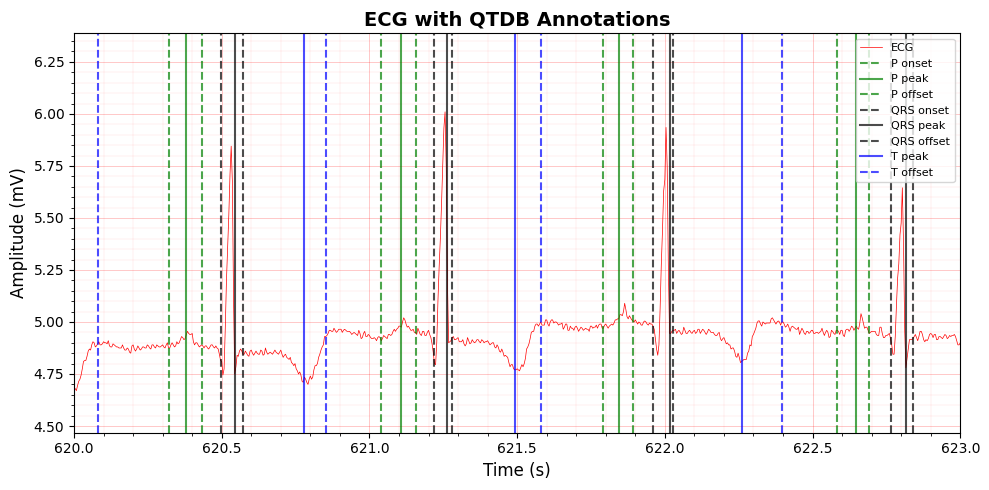

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


In [16]:
start = 620
plot_ecg(ecg_p, fs, time_range=(start, start+3), qrs_events=qrs_events, p_events=p_events, t_events=t_events, title="ECG with QTDB Annotations")
